The purpose of this notebook will be to investigate the effect of the auditory primer on the brain's processing of the tactile stimulus. This will be achieved by looking at the average trial for the same subject between the TO and CISI protocols, and computing channel-by-channel MI for two windows. The first window will be before tactile onset (-400 ms to 0 ms). The second window is after tactile onset (0 ms to +400 ms). This will allow us to analyze top-down processing (prediction of stimulus) and bottom-up processing (reaction to stimulus). The hope is that there will be differences in the heatmaps of TO vs. CISI. 

In [3]:
import mne
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

In [4]:
def load_subject_epochs(
    subject_num,
    cisi_root=Path("../data/raw/P1-20251027T182958Z-1-001/P1/"),
    to_root=Path("../data/raw/BLT/"),
    zscore=True,
    sfreq=512
):
    """
    Loads CISI and TO epochs for a single subject.
    Extracts auditory-centered epochs (index 0::2), so the window
    includes the pre-auditory baseline and the tactile response.

    Returns:
        cisi_ep  -> (60, 32, 1792)
        to_ep    -> (60, 32, 1792)
    """

    # === 1. Load CISI ===
    cisi_file = cisi_root / f"binepochs filtered ICArej P1AvgBOS{subject_num}.set"
    cisi_epochs = mne.io.read_epochs_eeglab(cisi_file)
    cisi_aud_epochs = cisi_epochs[0::2].copy().get_data()

    # === 2. Load TO ===
    to_file = to_root / f"binepochs filtered ICArej BLTAvgBOS{subject_num}.set"
    to_epochs = mne.io.read_epochs_eeglab(to_file)
    to_aud_epochs = to_epochs[0::2].copy().get_data()

    # === 3. Define baseline mask (-500 to 0 ms) ===
    times = cisi_epochs.times * 1000  # convert to ms
    baseline_mask = (times >= -500) & (times <= 0)

    # === 4. Baseline-based z-scoring (per channel per epoch) ===
    if zscore:

        def zscore_baseline(ep):
            # ep: (60, 32, 1792)
            baseline = ep[:, :, baseline_mask]  # (60, 32, baseline_pts)
            mean = baseline.mean(axis=2, keepdims=True)
            std = baseline.std(axis=2, keepdims=True) + 1e-8
            return (ep - mean) / std

        cisi_aud_epochs = zscore_baseline(cisi_aud_epochs)
        to_aud_epochs   = zscore_baseline(to_aud_epochs)

    return cisi_aud_epochs, to_aud_epochs



def load_all_subjects(subject_list):
    """
    Returns:
        cisi_all -> (n_subjects, 60, 32, 1792)
        to_all   -> (n_subjects, 60, 32, 1792)
    """

    cisi_all = []
    to_all = []

    for s in subject_list:
        print(f"Loading Subject {s} ...")
        cisi_ep, to_ep = load_subject_epochs(s)
        cisi_all.append(cisi_ep)
        to_all.append(to_ep)

    return np.array(cisi_all), np.array(to_all)


In [5]:
subjects = [2, 3, 5, 6, 7, 8, 9, 10, 11, 12, 13, 15, 16, 17]   # or however many you have

cisi_all, to_all = load_all_subjects(subjects)

print(cisi_all.shape)   # (n_subj, 60, 32, 1792)
print(to_all.shape)     # (n_subj, 60, 32, 1792)


Loading Subject 2 ...
Extracting parameters from c:\Users\Rinta\Documents\Classes\PSYC 4745\Research Project\CISI Repo\Phys-Cog-CISI-Group\notebooks\..\data\raw\P1-20251027T182958Z-1-001\P1\binepochs filtered ICArej P1AvgBOS2.set...
Not setting metadata
120 matching events found


C:\Users\Rinta\AppData\Local\Temp\ipykernel_31304\2405077424.py:20: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  cisi_epochs = mne.io.read_epochs_eeglab(cisi_file)


No baseline correction applied
0 projection items activated
Ready.
Extracting parameters from c:\Users\Rinta\Documents\Classes\PSYC 4745\Research Project\CISI Repo\Phys-Cog-CISI-Group\notebooks\..\data\raw\BLT\binepochs filtered ICArej BLTAvgBOS2.set...
Not setting metadata
120 matching events found
No baseline correction applied
0 projection items activated
Ready.


C:\Users\Rinta\AppData\Local\Temp\ipykernel_31304\2405077424.py:25: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  to_epochs = mne.io.read_epochs_eeglab(to_file)


Loading Subject 3 ...
Extracting parameters from c:\Users\Rinta\Documents\Classes\PSYC 4745\Research Project\CISI Repo\Phys-Cog-CISI-Group\notebooks\..\data\raw\P1-20251027T182958Z-1-001\P1\binepochs filtered ICArej P1AvgBOS3.set...
Not setting metadata
120 matching events found
No baseline correction applied
0 projection items activated
Ready.
Extracting parameters from c:\Users\Rinta\Documents\Classes\PSYC 4745\Research Project\CISI Repo\Phys-Cog-CISI-Group\notebooks\..\data\raw\BLT\binepochs filtered ICArej BLTAvgBOS3.set...


...

Loading Subject 17 ...
Extracting parameters from c:\Users\Rinta\Documents\Classes\PSYC 4745\Research Project\CISI Repo\Phys-Cog-CISI-Group\notebooks\..\data\raw\P1-20251027T182958Z-1-001\P1\binepochs filtered ICArej P1AvgBOS17.set...
Not setting metadata
120 matching events found
No baseline correction applied
0 projection items activated
Ready.


C:\Users\Rinta\AppData\Local\Temp\ipykernel_31304\2405077424.py:20: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  cisi_epochs = mne.io.read_epochs_eeglab(cisi_file)


Extracting parameters from c:\Users\Rinta\Documents\Classes\PSYC 4745\Research Project\CISI Repo\Phys-Cog-CISI-Group\notebooks\..\data\raw\BLT\binepochs filtered ICArej BLTAvgBOS17.set...
Not setting metadata
120 matching events found
No baseline correction applied
0 projection items activated
Ready.


C:\Users\Rinta\AppData\Local\Temp\ipykernel_31304\2405077424.py:25: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  to_epochs = mne.io.read_epochs_eeglab(to_file)


(14, 60, 32, 1792)
(14, 60, 32, 1792)


In [22]:
import numpy as np
import matplotlib.pyplot as plt

def plot_all_channels_with_windows(
    avg_trial, ch_names,
    sfreq=512,
    full_t_start_ms=-500,
    plot_start_ms=-500,
    plot_end_ms=1000,
    windows={
        "pre_auditory_baseline":  (-500, 0),
        "post_auditory_pre_tact": (0, 300),
        "early_tactile":          (500, 560),
        "mid_tactile":            (560, 650),
        "late_tactile":           (700, 800)
    }
):
    """
    avg_trial: (32, timepoints)
    """

    n_channels, n_times = avg_trial.shape

    # Full time axis (same length as the data)
    time_ms = np.linspace(
        full_t_start_ms,
        full_t_start_ms + (n_times / sfreq) * 1000,
        n_times
    )

    # Mask to keep only -500 to +1500 ms
    mask = (time_ms >= plot_start_ms) & (time_ms <= plot_end_ms)
    
    time_w = time_ms[mask]
    data_w = avg_trial[:, mask]

    # Different colors for each window
    window_colors = [
        'tab:blue', 'tab:orange', 'tab:green',
        'tab:red', 'tab:purple', 'tab:brown'
    ]

    fig, axes = plt.subplots(4, 8, figsize=(22, 10), sharex=True, sharey=True)
    axes = axes.ravel()

    for ch in range(n_channels):
        ax = axes[ch]
        ax.plot(time_w, data_w[ch], linewidth=1)

        # Colorful windows
        for color, (name, (w_start, w_end)) in zip(window_colors, windows.items()):
            # Clip window to plotting region
            w0 = max(w_start, plot_start_ms)
            w1 = min(w_end,   plot_end_ms)
            ax.axvspan(w0, w1, color=color, alpha=0.20)

        # Auditory onset at 0 ms
        ax.axvline(0, color='black', linestyle='--', linewidth=1)

        # Tactile onset at +500 ms
        ax.axvline(500, color='red', linestyle='--', linewidth=1)

        ax.set_title(ch_names[ch], fontsize=8)
        ax.grid(True, alpha=0.2)

    fig.supxlabel("Time (ms)", fontsize=14)
    fig.supylabel("Amplitude (z-scored)", fontsize=14)
    fig.suptitle("Average Trial with All Analysis Windows (−500 to +1500 ms)", fontsize=18)

    plt.tight_layout(rect=[0,0,1,0.95])
    plt.show()


In [19]:
def plot_overlay_all_channels(
    dataA, dataB, ch_names,
    sfreq=512,
    full_t_start_ms=-500,
    plot_start_ms=-500,
    plot_end_ms=1000,
    windows={
        "pre_auditory_baseline":  (-500, 0),
        "post_auditory_pre_tact": (0, 300),
        "early_tactile":          (500, 560),
        "mid_tactile":            (560, 650),
        "late_tactile":           (700, 800)
    },
    labelA="Dataset A",
    labelB="Dataset B"
):
    n_channels, n_times = dataA.shape

    # Full time axis
    time_ms = np.linspace(
        full_t_start_ms,
        full_t_start_ms + (n_times / sfreq) * 1000,
        n_times
    )

    # Apply mask
    mask = (time_ms >= plot_start_ms) & (time_ms <= plot_end_ms)
    time_w = time_ms[mask]
    A_w = dataA[:, mask]
    B_w = dataB[:, mask]

    # Window colors
    window_colors = [
        'tab:blue', 'tab:orange', 'tab:green',
        'tab:red', 'tab:purple', 'tab:brown'
    ]

    fig, axes = plt.subplots(4, 8, figsize=(22, 10), sharex=True, sharey=True)
    axes = axes.ravel()

    for ch in range(n_channels):
        ax = axes[ch]

        ax.plot(time_w, A_w[ch], label=labelA, linewidth=1)
        ax.plot(time_w, B_w[ch], label=labelB, linewidth=1)

        # Window shading (distinct colors)
        for color, (name, (w_start, w_end)) in zip(window_colors, windows.items()):
            w0 = max(w_start, plot_start_ms)
            w1 = min(w_end,   plot_end_ms)
            ax.axvspan(w0, w1, color=color, alpha=0.20)

        # Auditory onset
        ax.axvline(0, color='black', linestyle='--', linewidth=1)
        # Tactile onset
        ax.axvline(500, color='red', linestyle='--', linewidth=1)

        ax.set_title(ch_names[ch], fontsize=8)
        ax.grid(True, alpha=0.2)

    fig.supxlabel("Time (ms)")
    fig.supylabel("Amplitude (z-scored)")
    fig.suptitle(f"{labelA} vs {labelB}: Overlay (−500 to +1500 ms)")

    # Single legend outside axes
    fig.legend([labelA, labelB], loc="upper right")

    plt.tight_layout(rect=[0,0,1,0.95])
    plt.show()


In [20]:
# Load subject 2 for quick testing
sub = 2
cisi_ep, to_ep = load_subject_epochs(sub)

# Compute average tactile trial for that subject
cisi_avg = cisi_ep.mean(axis=0)   # (32,1792)
to_avg   = to_ep.mean(axis=0)

ch_names = mne.io.read_epochs_eeglab(Path("../data/raw/P1-20251027T182958Z-1-001/P1/binepochs filtered ICArej P1AvgBOS2.set")).ch_names

Extracting parameters from c:\Users\Rinta\Documents\Classes\PSYC 4745\Research Project\CISI Repo\Phys-Cog-CISI-Group\notebooks\..\data\raw\P1-20251027T182958Z-1-001\P1\binepochs filtered ICArej P1AvgBOS2.set...
Not setting metadata
120 matching events found
No baseline correction applied
0 projection items activated
Ready.


C:\Users\Rinta\AppData\Local\Temp\ipykernel_31304\2405077424.py:20: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  cisi_epochs = mne.io.read_epochs_eeglab(cisi_file)
C:\Users\Rinta\AppData\Local\Temp\ipykernel_31304\2405077424.py:25: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  to_epochs = mne.io.read_epochs_eeglab(to_file)


Extracting parameters from c:\Users\Rinta\Documents\Classes\PSYC 4745\Research Project\CISI Repo\Phys-Cog-CISI-Group\notebooks\..\data\raw\BLT\binepochs filtered ICArej BLTAvgBOS2.set...
Not setting metadata
120 matching events found
No baseline correction applied
0 projection items activated
Ready.
Extracting parameters from c:\Users\Rinta\Documents\Classes\PSYC 4745\Research Project\CISI Repo\Phys-Cog-CISI-Group\notebooks\..\data\raw\P1-20251027T182958Z-1-001\P1\binepochs filtered ICArej P1AvgBOS2.set...
Not setting metadata
120 matching events found
No baseline correction applied
0 projection items activated
Ready.


C:\Users\Rinta\AppData\Local\Temp\ipykernel_31304\732449613.py:9: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  ch_names = mne.io.read_epochs_eeglab(Path("../data/raw/P1-20251027T182958Z-1-001/P1/binepochs filtered ICArej P1AvgBOS2.set")).ch_names


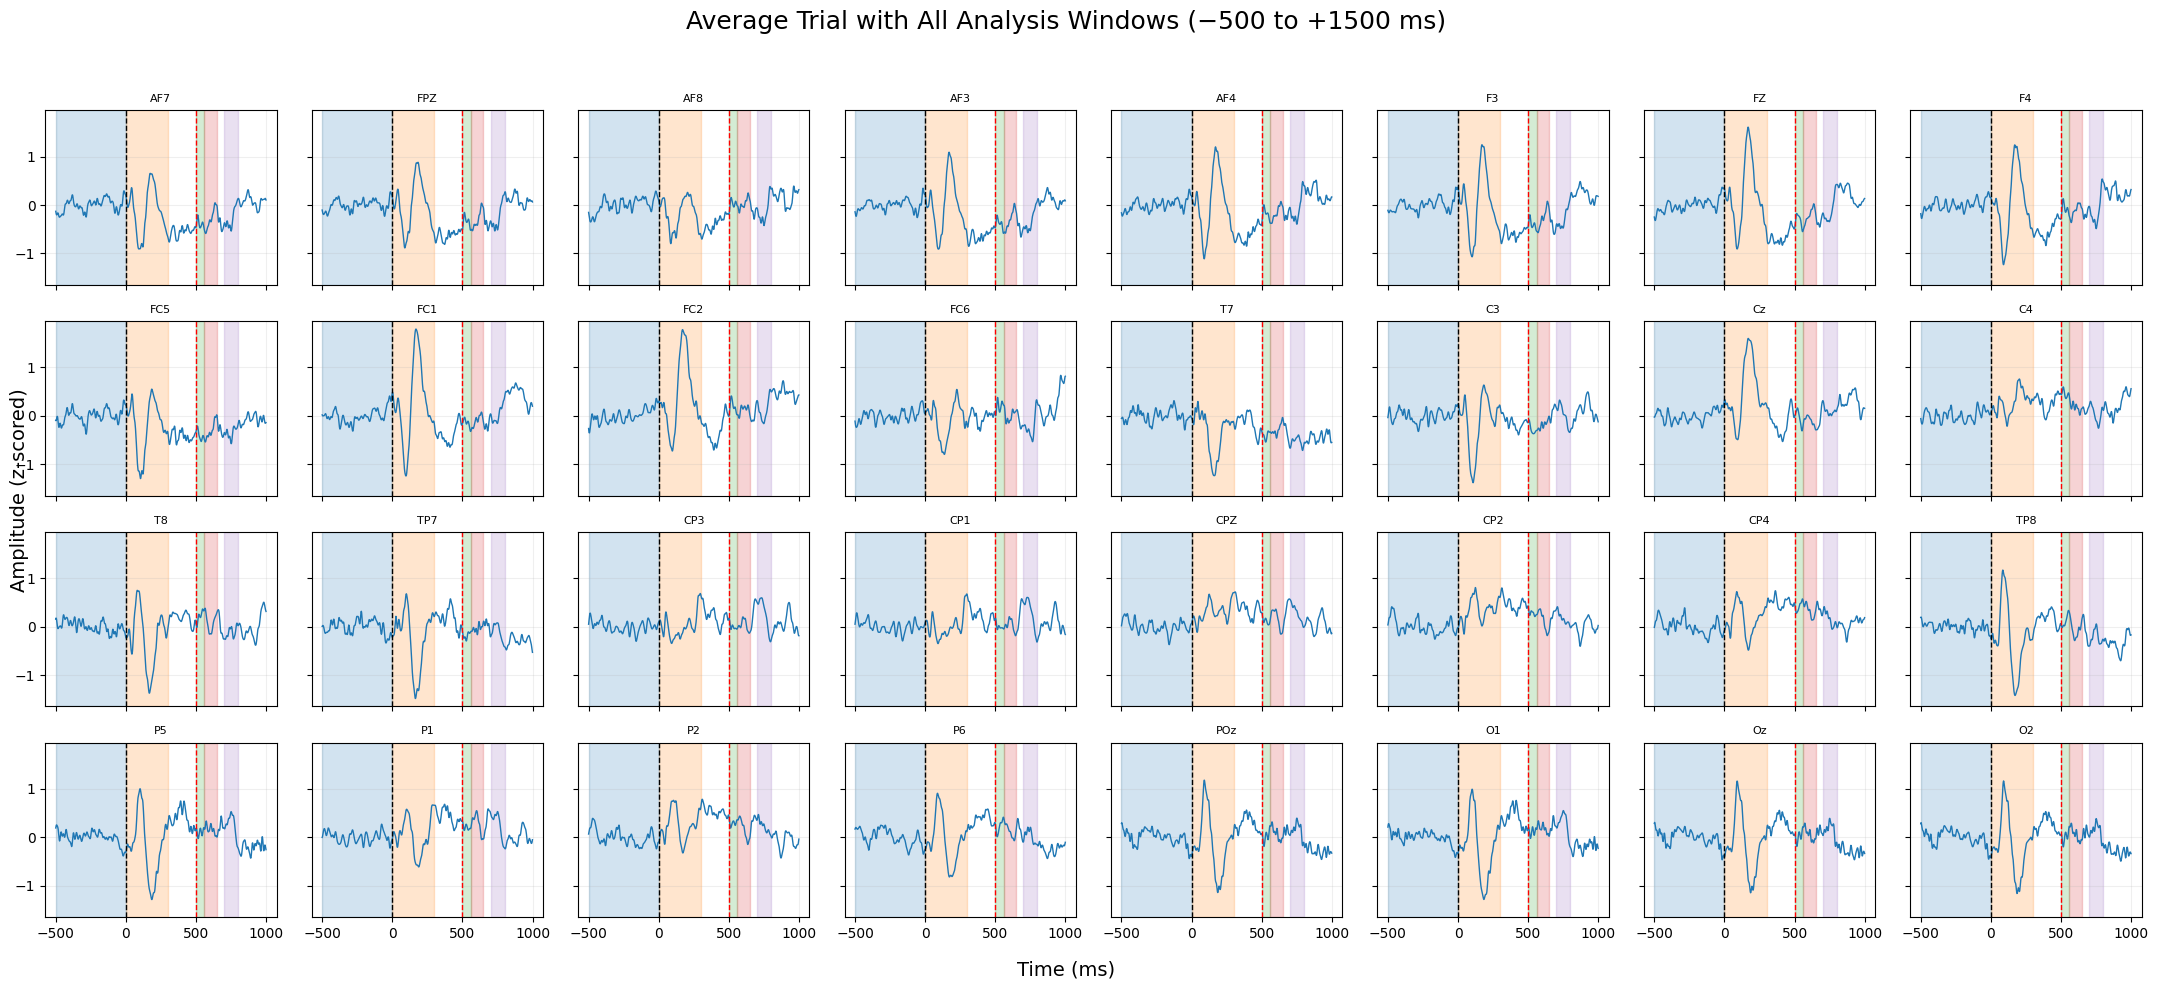

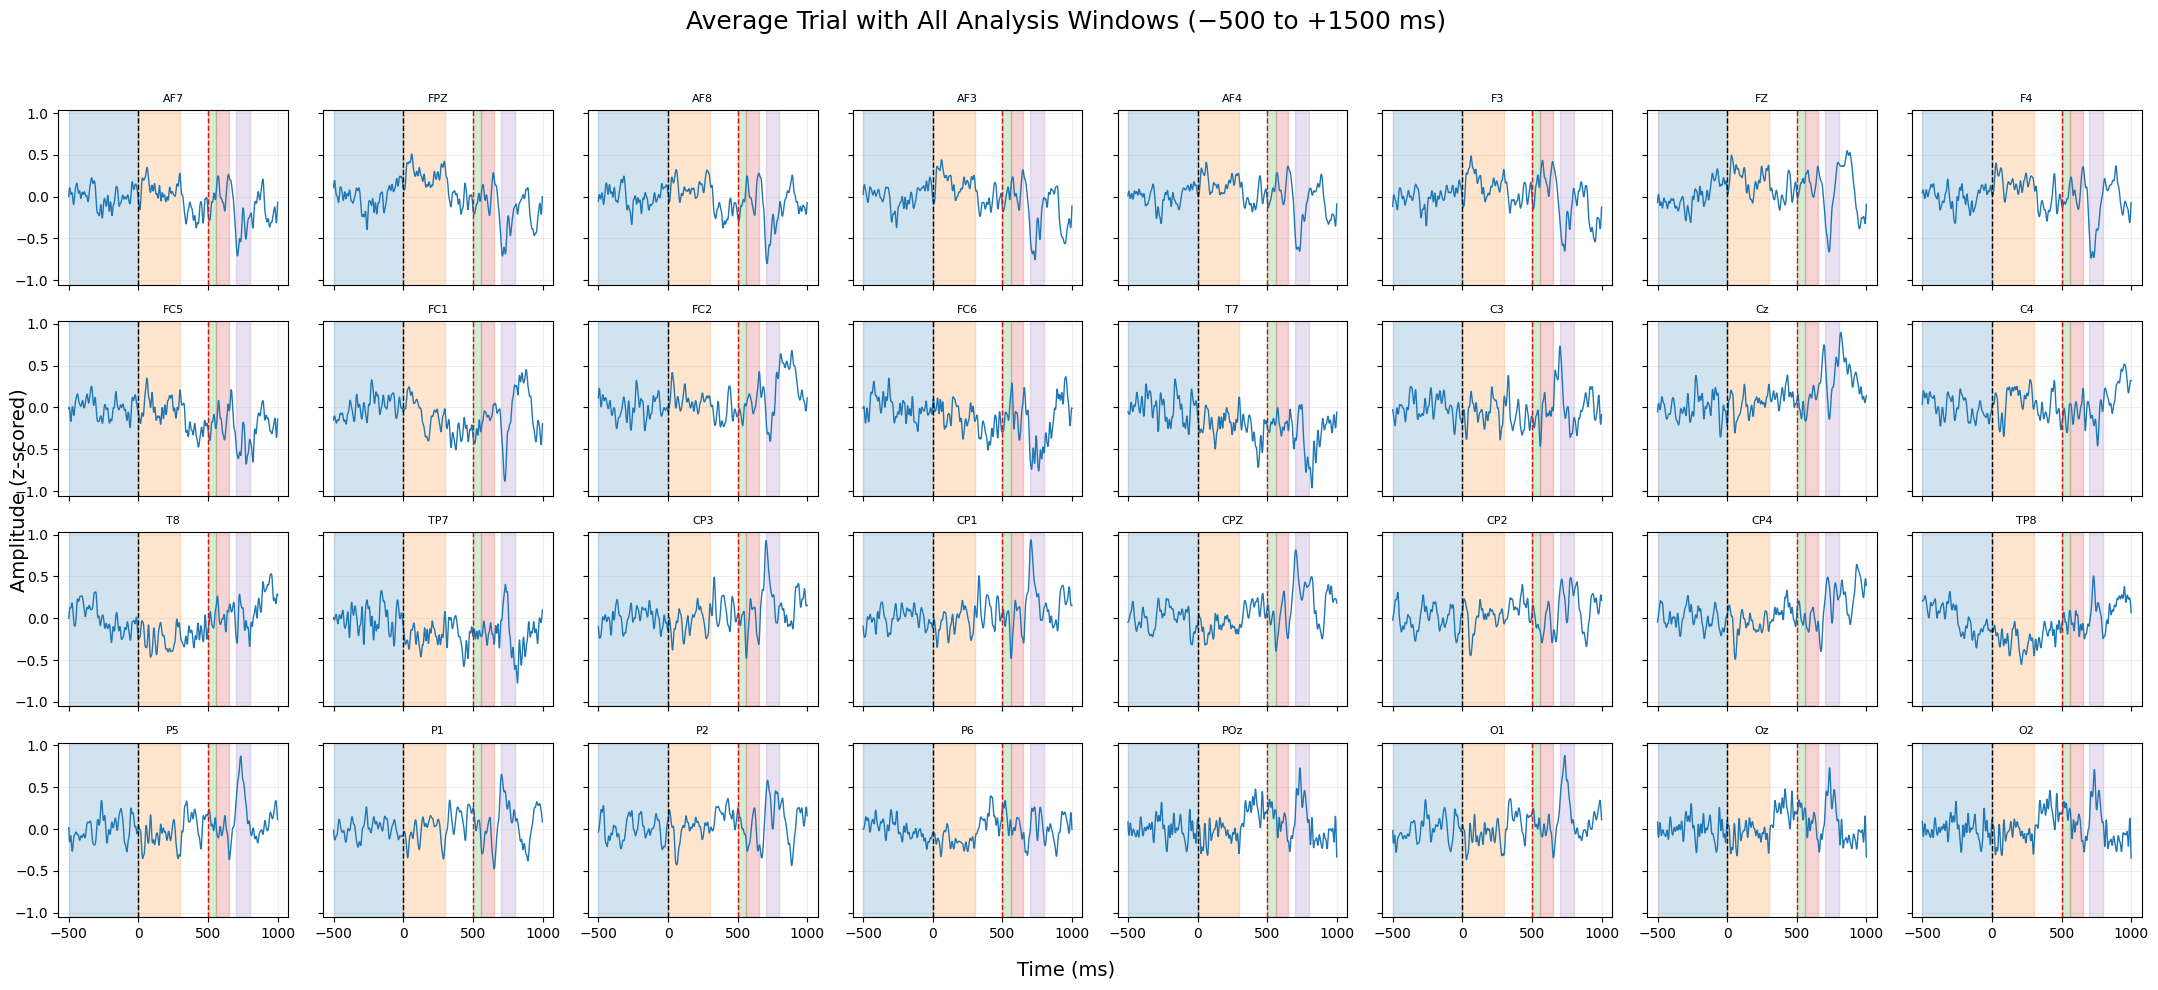

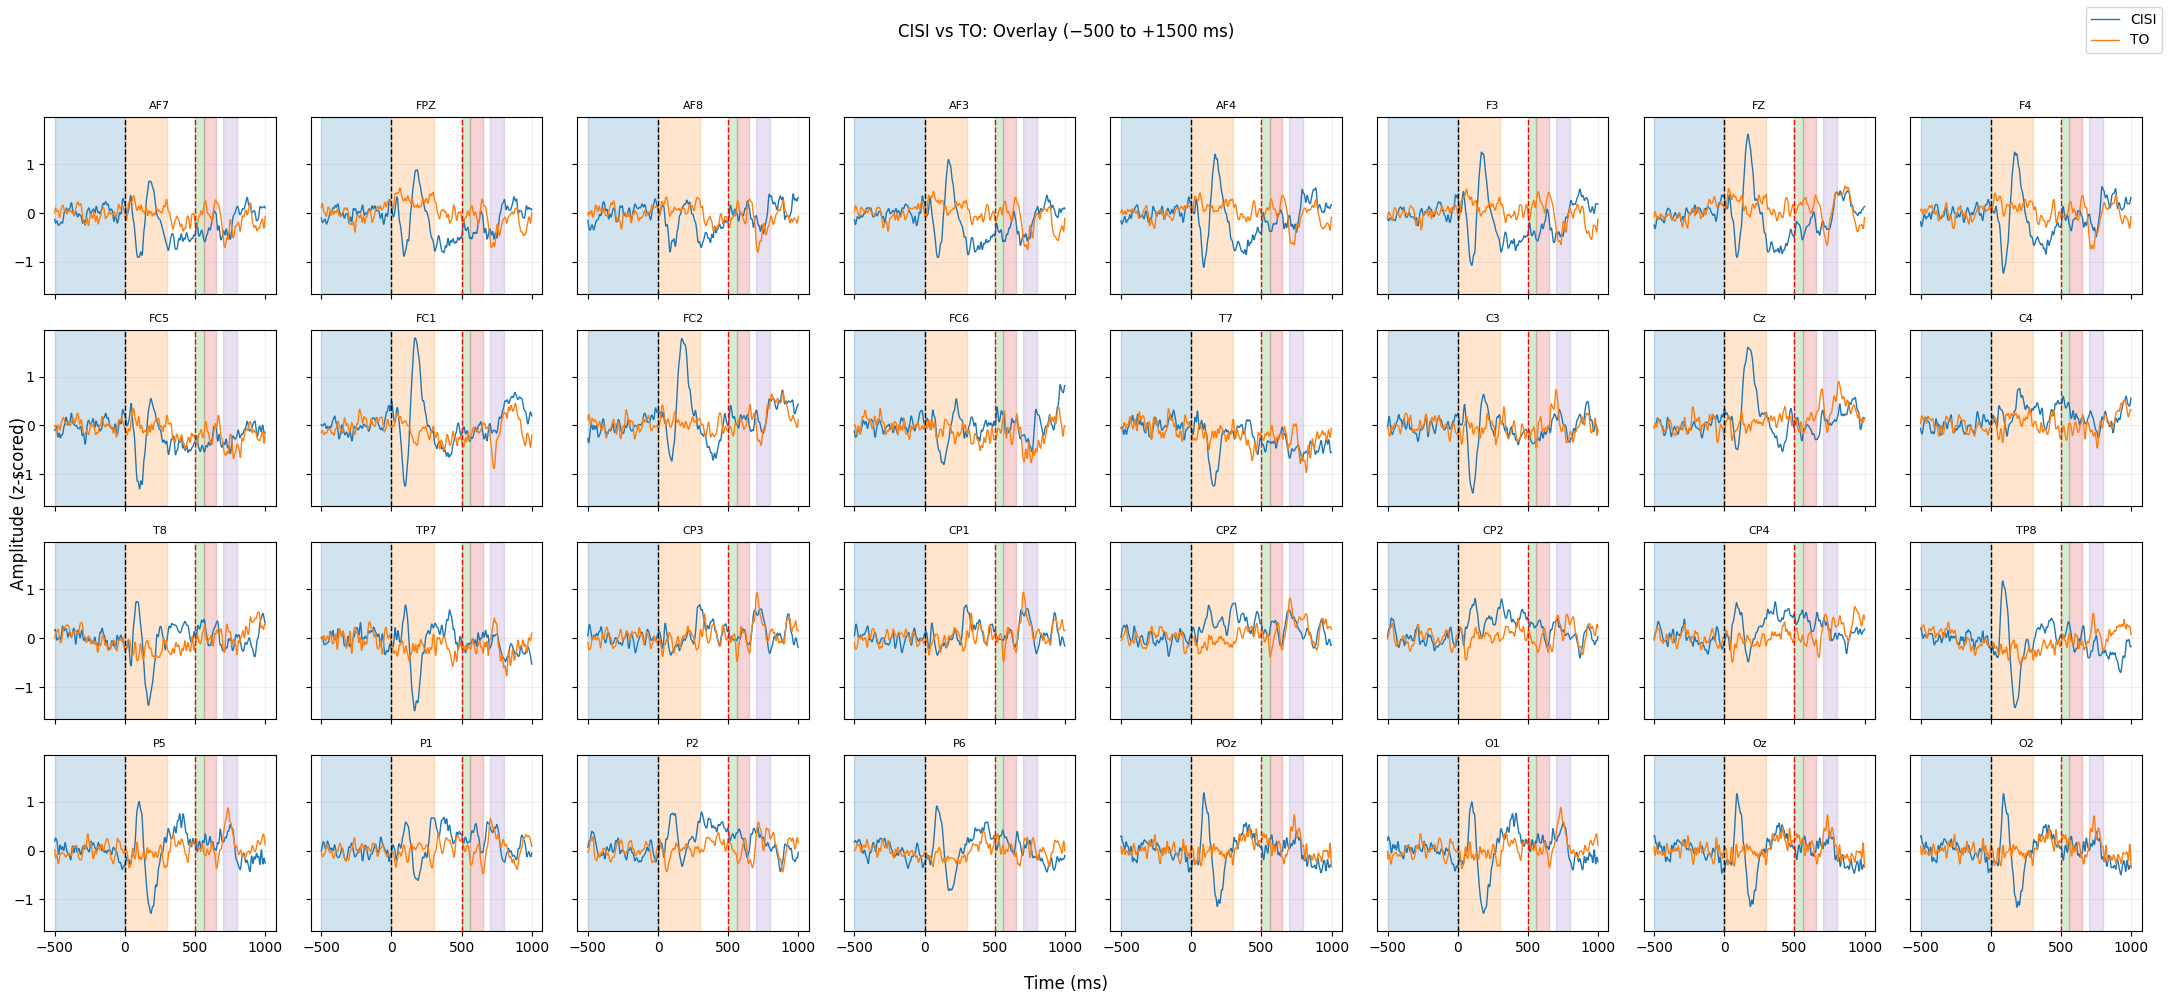

In [23]:
# Plot
plot_all_channels_with_windows(cisi_avg, ch_names)
plot_all_channels_with_windows(to_avg, ch_names)
plot_overlay_all_channels(cisi_avg, to_avg, ch_names,
                          labelA="CISI", labelB="TO")


In [10]:
import numpy as np

# --- Your time axis in ms ---
# Example: from -500 ms to +3000 ms over 1792 samples.
# You already have times in your MNE objects, but this rebuilds it for clarity.

def build_time_axis(n_times, sfreq=512, t_start_ms=-500):
    return np.linspace(
        t_start_ms,
        t_start_ms + (n_times / sfreq) * 1000,
        n_times
    )

# --- Compute AUC for one window ---
def compute_auc_window(epochs, times, window):
    """
    epochs: (trials, channels, time)
    times: time axis in ms
    window: (start_ms, end_ms)
    
    Returns: AUC → (trials, channels)
    """
    start, end = window
    mask = (times >= start) & (times <= end)

    dt = (times[1] - times[0]) / 1000.0  # ms→s

    # integrate over time axis
    auc = epochs[:, :, mask].sum(axis=2) * dt

    return auc  # shape (trials, channels)


# --- Compute AUC for all windows & all subjects ---
def compute_all_windows(cisi_all, to_all, windows, sfreq=512):
    """
    cisi_all: (subjects, 60, 32, 1792)
    to_all:   (subjects, 60, 32, 1792)
    
    Returns:
        cisi_auc[window] → (subjects, trials, channels)
        to_auc[window]   → same
    """

    n_subjects, n_trials, n_channels, n_times = cisi_all.shape
    times = build_time_axis(n_times, sfreq)

    cisi_auc = {w: [] for w in windows}
    to_auc   = {w: [] for w in windows}

    for wname, (w_start, w_end) in windows.items():
        print(f"Processing window '{wname}' ({w_start}–{w_end} ms) ...")

        # Compute per subject
        cisi_auc[wname] = np.array([
            compute_auc_window(cisi_all[s], times, (w_start, w_end))
            for s in range(n_subjects)
        ])  # → (subjects, trials, channels)

        to_auc[wname] = np.array([
            compute_auc_window(to_all[s], times, (w_start, w_end))
            for s in range(n_subjects)
        ])

    return cisi_auc, to_auc


In [24]:
windows={
        "pre_auditory_baseline":  (-500, 0),
        "post_auditory_pre_tact": (0, 300),
        "early_tactile":          (500, 560),
        "mid_tactile":            (560, 650),
        "late_tactile":           (700, 800)
    }

cisi_auc, to_auc = compute_all_windows(cisi_all, to_all, windows)

cisi_auc["early_tactile"].shape

cisi_mean = cisi_auc["early_tactile"].mean(axis=1)   # (14, 32)
to_mean   = to_auc["early_tactile"].mean(axis=1)     # (14, 32)

from scipy.stats import ttest_rel
tvals, pvals = ttest_rel(cisi_mean, to_mean, axis=0)

diff_auc = (cisi_mean - to_mean)   # (14,32)
group_avg_diff = diff_auc.mean(axis=0)


Processing window 'pre_auditory_baseline' (-500–0 ms) ...
Processing window 'post_auditory_pre_tact' (0–300 ms) ...
Processing window 'early_tactile' (500–560 ms) ...
Processing window 'mid_tactile' (560–650 ms) ...
Processing window 'late_tactile' (700–800 ms) ...


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mne.viz import plot_topomap

def plot_multiwindow_topomaps(
    cisi_auc,             # dict: window → (subjects, trials, channels)
    to_auc,               # dict: same
    windows,              # dict: window → (start_ms, end_ms)
    info,                 # MNE info object (for electrode positions)
    vmax_factor=1.0,      # scale factor for topomap normalization
    cmap_main="viridis",
    cmap_diff="coolwarm"
):

    window_names = list(windows.keys())
    n_windows = len(window_names)

    # Prepare figure: 5 rows × 3 columns
    fig, axes = plt.subplots(
        n_windows, 3,
        figsize=(14, 3 * n_windows),
        constrained_layout=True
    )

    if n_windows == 1:
        axes = axes.reshape(1, 3)  # fix shape if only 1 window

    # Compute global max for consistent color scaling
    all_vals = []

    for w in window_names:
        all_vals.append(cisi_auc[w].mean(axis=(0,1)))
        all_vals.append(to_auc[w].mean(axis=(0,1)))

    global_max = np.max(np.abs(np.concatenate(all_vals))) * vmax_factor

    for row, wname in enumerate(window_names):
        # === Compute AUC means across subjects & trials ===
        cisi_mean = cisi_auc[wname].mean(axis=(0,1))  # (32,)
        to_mean   = to_auc[wname].mean(axis=(0,1))
        diff_mean = cisi_mean - to_mean

        # === Column 1: CISI topomap ===
        plt.sca(axes[row, 0])
        plot_topomap(
            cisi_mean, info,
            cmap=cmap_main,
            vmin=-global_max, vmax=global_max,
            contours=0, outlines="head"
        )
        axes[row, 0].set_title(f"{wname}\nCISI")

        # === Column 2: TO topomap ===
        plt.sca(axes[row, 1])
        plot_topomap(
            to_mean, info,
            cmap=cmap_main,
            vmin=-global_max, vmax=global_max,
            contours=0, outlines="head"
        )
        axes[row, 1].set_title("TO")

        # === Column 3: CISI − TO difference topomap ===
        diff_max = np.max(np.abs(diff_mean))
        plt.sca(axes[row, 2])
        plot_topomap(
            diff_mean, info,
            cmap=cmap_diff,
            vmin=-diff_max, vmax=diff_max,
            contours=0, outlines="head"
        )
        axes[row, 2].set_title("CISI − TO")

    fig.suptitle("AUC Topographies Across All Windows", fontsize=20)
    plt.show()


Extracting parameters from c:\Users\Rinta\Documents\Classes\PSYC 4745\Research Project\CISI Repo\Phys-Cog-CISI-Group\notebooks\..\data\raw\P1-20251027T182958Z-1-001\P1\binepochs filtered ICArej P1AvgBOS2.set...
Not setting metadata
120 matching events found
No baseline correction applied
0 projection items activated
Ready.


C:\Users\Rinta\AppData\Local\Temp\ipykernel_31304\176744828.py:5: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  info=mne.io.read_epochs_eeglab(Path("../data/raw/P1-20251027T182958Z-1-001/P1/binepochs filtered ICArej P1AvgBOS2.set")).info,   # from your MNE-loaded dataset


TypeError: plot_topomap() got an unexpected keyword argument 'vmin'

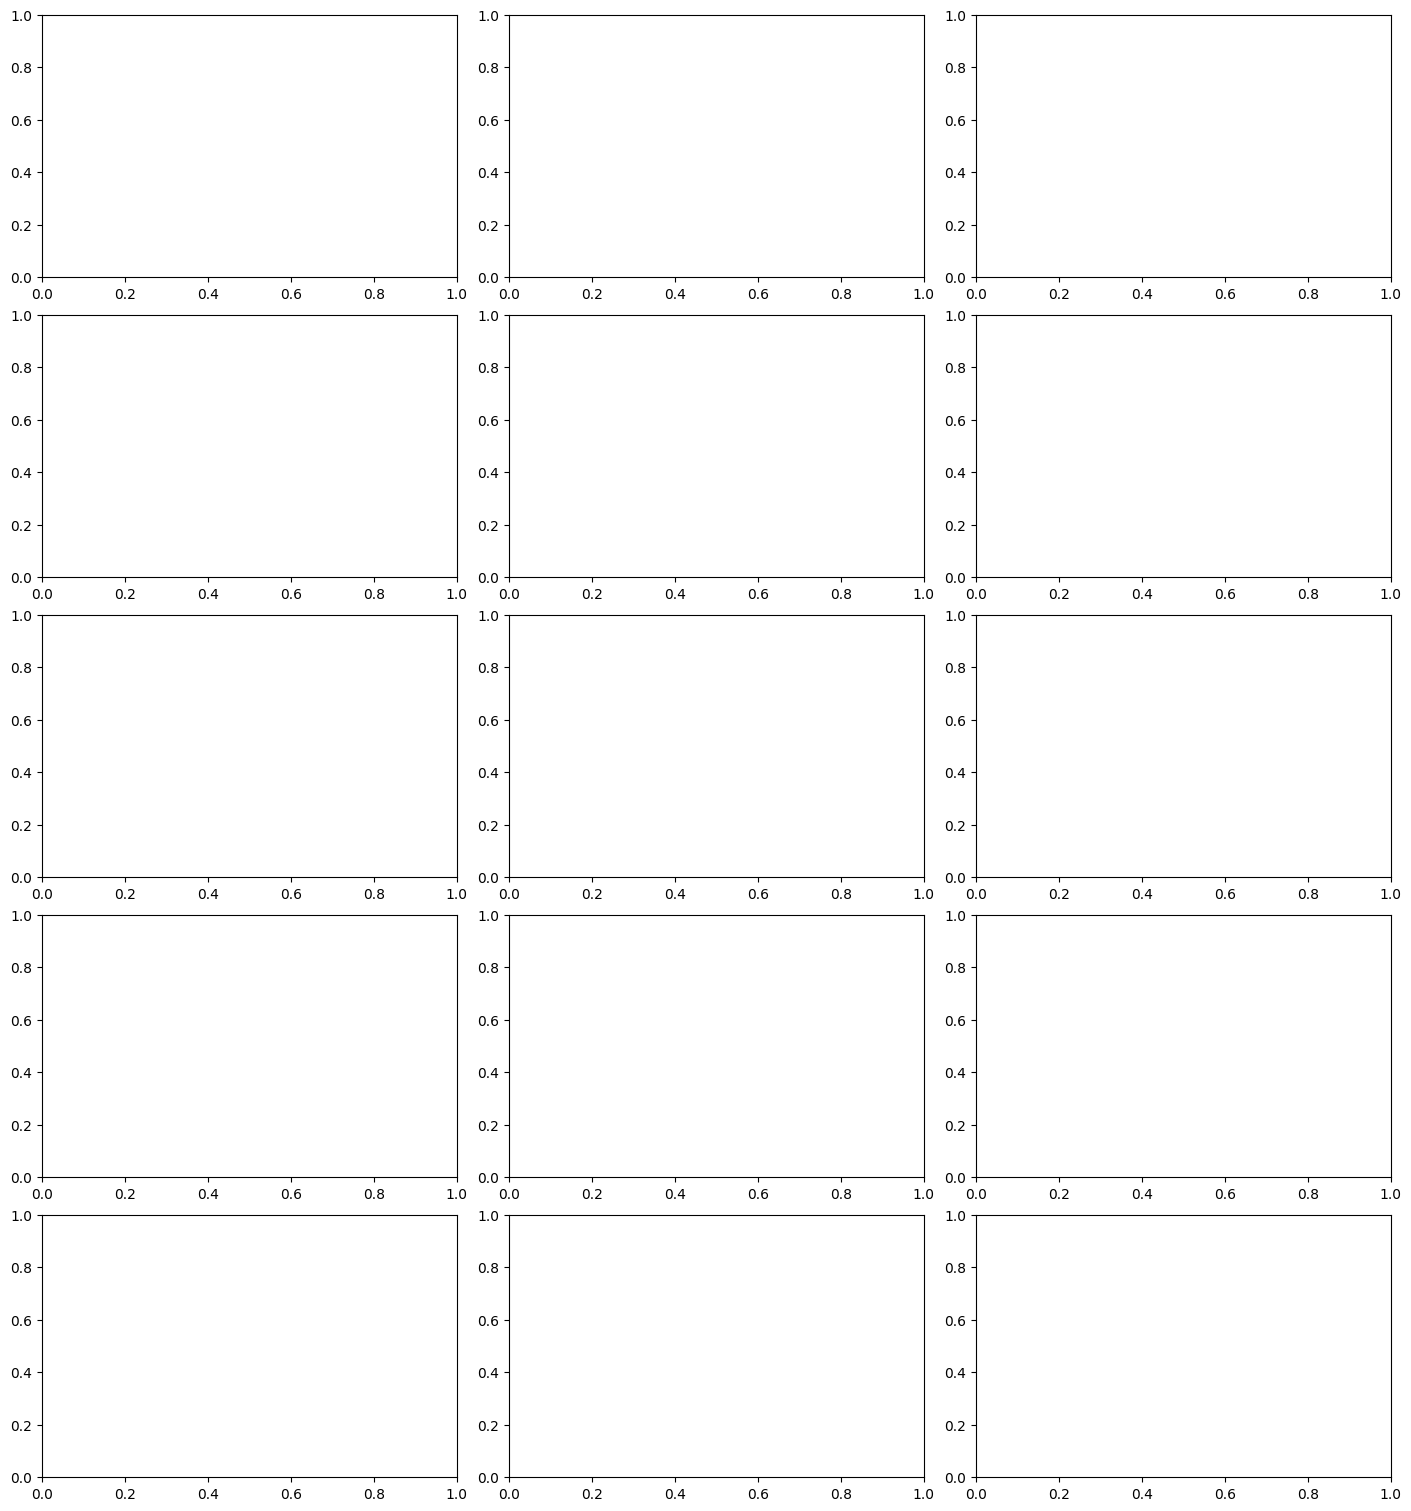

In [26]:
plot_multiwindow_topomaps(
    cisi_auc=cisi_auc,
    to_auc=to_auc,
    windows=windows,
    info=mne.io.read_epochs_eeglab(Path("../data/raw/P1-20251027T182958Z-1-001/P1/binepochs filtered ICArej P1AvgBOS2.set")).info,   # from your MNE-loaded dataset
    vmax_factor=1.0          # adjust if needed
)
